# Interaction and nonlinear terms in the linear model (not built)

All 15 pairwise products, 6 squares and 2 one-sided terms of the submitted model's inputs and
the last speed, each added to the submitted config on the six yearly folds (forward selection;
a step needs >= 0.3% on >= 4 folds). Study: `python -m training.interactions`; write-up
`docs/interactions.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import interactions as it

d = pd.read_csv(it.EXPERIMENTS / "interactions.csv")
ref = d[d.set == "reference"].set_index("fold")
d["rel"] = d["all"] / d.fold.map(ref["all"])
d["slow rel"] = d["slow wind"] / d.fold.map(ref["slow wind"])
g = d[d.set != "reference"].groupby("set")
summary = pd.DataFrame({
    "six folds %": 100 * (np.exp(g["rel"].apply(lambda s: np.log(s).mean())) - 1),
    "folds won": g["rel"].apply(lambda s: int((s < 1).sum())),
    "slow runs %": 100 * (np.exp(g["slow rel"].apply(lambda s: np.log(s).mean())) - 1),
}).sort_values("six folds %")
summary.round(2)

,six folds %,folds won,slow runs %
set,,,
sq:dhcs,-0.16,3,-1.26
int:ch*density,-0.02,5,0.25
int:density*last,0.05,1,-0.04
int:bt*last,0.05,3,-0.83
int:bt*xray,0.06,4,-0.14
int:xray*last,0.06,2,-0.42
int:ch*xray,0.11,2,0.64
hinge:dhcs>0,0.12,0,-0.00
int:dhcs*xray,0.12,5,-1.96


## By fold (% vs reference)

fold,2019,2020,2021,2022,2023,2024
set,,,,,,
sq:dhcs,-0.38,0.08,-0.73,0.43,0.33,-0.70
int:ch*density,0.17,-0.06,-0.07,-0.02,-0.06,-0.07
int:density*last,-0.01,0.09,0.02,0.03,0.12,0.06
int:bt*last,-0.26,-0.06,0.53,-0.20,0.02,0.29
int:bt*xray,-0.11,0.27,0.35,-0.04,-0.11,-0.01
int:xray*last,-0.02,0.05,0.20,0.07,0.07,-0.04
int:ch*xray,-0.02,0.21,0.53,0.21,0.02,-0.28
hinge:dhcs>0,0.08,0.01,0.29,0.07,0.03,0.25
int:dhcs*xray,-0.15,-0.17,-0.54,-0.03,1.64,-0.00


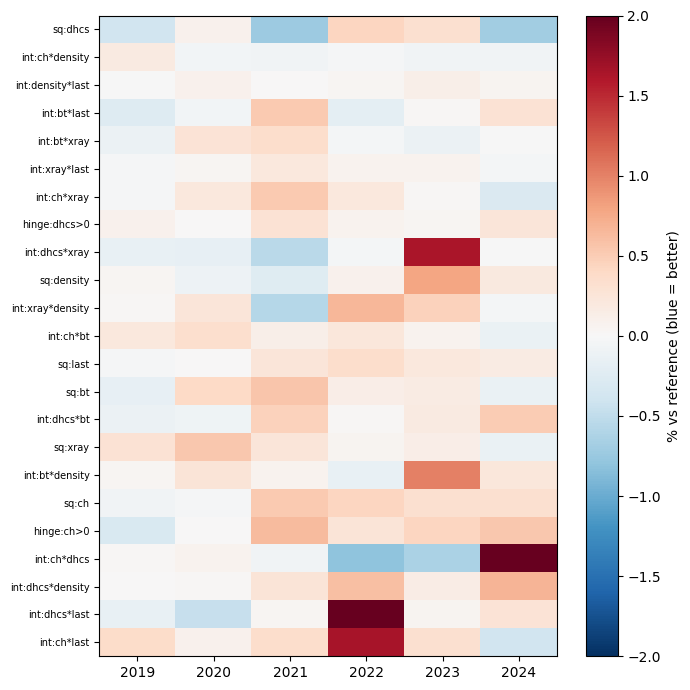

In [2]:
byf = 100 * (d[d.set != "reference"].pivot(index="set", columns="fold", values="rel") - 1)
byf = byf.loc[summary.index]
fig, ax = plt.subplots(figsize=(7, 7))
im = ax.imshow(byf, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_yticks(range(len(byf)), byf.index, fontsize=7)
ax.set_xticks(range(byf.shape[1]), byf.columns)
plt.colorbar(im, label="% vs reference (blue = better)")
plt.tight_layout()
byf.round(2)

No term gains 0.3% on 4 folds, so the selection stops at step 1. The 2024 fold (the pilot)
favours the current-sheet distance squared and the coronal hole x last speed; the other folds
don't.